# CLIP ile Çiçek Sınıflandırma — Genelleme ve Alternatif Model (3. Kişi)

Bu notebook; CLIP (OpenAI, `openai/clip-vit-base-patch32`) kullanarak 102 kategorilik çiçek veri setinde zero-shot ve few-shot sınıflandırma deneylerini, veri setinde olmayan türlerle genelleme testini, görüntü bozulmalarına dayanıklılık testini ve ana modellerle (EfficientNet-B0, MobileNetV3, EfficientNetV2-S) karşılaştırmayı içerir.

## 1. Kurulum

In [1]:
import json, torch
from transformers import CLIPModel, CLIPProcessor

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

with open("data/cat_to_name.json") as f:
    cat_to_name = json.load(f)   # {"1": "pink primrose", ...}
print("num classes:", len(cat_to_name))

/Applications/XAMPP/xamppfiles/htdocs/Flower-Species-Classification/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


device: mps


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


num classes: 102


## 2. Sınıf isimlerini metin prompt'una çevirme

In [2]:
class_ids = sorted(cat_to_name.keys(), key=int)          # ["1","2",...,"102"]
prompts = [f"a photo of a {cat_to_name[c]}, a type of flower" for c in class_ids]

text_inputs = processor(text=prompts, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print("text_features shape:", text_features.shape)

text_features shape: torch.Size([102, 512])


## 3. Test seti üzerinde zero-shot accuracy

In [3]:
from pathlib import Path
from PIL import Image

test_dir = Path("data/test")
test_items = []  # (image_path, true_class_id)
for class_dir in sorted(test_dir.iterdir(), key=lambda p: int(p.name)):
    for img_path in class_dir.glob("*.jpg"):
        test_items.append((img_path, class_dir.name))

print("total test images:", len(test_items))

class_id_to_idx = {c: i for i, c in enumerate(class_ids)}  # "1" -> 0, ...

@torch.no_grad()
def predict_batch(image_paths, batch_size=32):
    all_pred_idx = []
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=images, return_tensors="pt").to(device)
        image_features = model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        logits = image_features @ text_features.T  # cosine similarity (already normalized)
        pred_idx = logits.argmax(dim=-1).cpu().tolist()
        all_pred_idx.extend(pred_idx)
    return all_pred_idx

image_paths = [p for p, _ in test_items]
true_idx = [class_id_to_idx[c] for _, c in test_items]

pred_idx = predict_batch(image_paths)
correct = sum(p == t for p, t in zip(pred_idx, true_idx))
zero_shot_accuracy = correct / len(test_items)
print(f"Zero-shot accuracy: {zero_shot_accuracy:.4f} ({correct}/{len(test_items)})")

total test images: 819


Zero-shot accuracy: 0.6654 (545/819)


## 4. Inference hızı ve model boyutu (yarışma kriterleri 2 ve 3)

In [4]:
import time

# Inference speed: tek görüntü başına ortalama süre (batch_size=1, hocanın predict.py ile
# tek tek görüntü vereceği senaryoyu simüle eder)
warmup_paths = image_paths[:5]
timed_paths = image_paths[5:55]  # 50 görüntü üzerinden ortalama al

predict_batch(warmup_paths, batch_size=1)  # warm-up, cache/JIT etkisini dışla

start = time.perf_counter()
predict_batch(timed_paths, batch_size=1)
elapsed = time.perf_counter() - start
inference_ms_per_image = (elapsed / len(timed_paths)) * 1000
print(f"Inference speed: {inference_ms_per_image:.2f} ms/image (device={device})")

# Model boyutu: state_dict'teki tüm parametrelerin bellekte kapladığı yer (MB)
param_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
model_size_mb = param_bytes / (1024 ** 2)
print(f"Model size: {model_size_mb:.2f} MB")

Inference speed: 28.66 ms/image (device=mps)
Model size: 577.08 MB


In [5]:
import json
from pathlib import Path

Path("results").mkdir(exist_ok=True)

clip_metrics = {
    "model_name": "CLIP-ViT-B/32 (zero-shot)",
    "accuracy": round(zero_shot_accuracy, 4),
    "inference_ms_per_image": round(inference_ms_per_image, 2),
    "model_size_mb": round(model_size_mb, 2),
    "device": device,
    "num_test_images": len(test_items),
}

with open("results/clip_metrics.json", "w") as f:
    json.dump(clip_metrics, f, indent=2, ensure_ascii=False)

clip_metrics

{'model_name': 'CLIP-ViT-B/32 (zero-shot)',
 'accuracy': 0.6654,
 'inference_ms_per_image': 28.66,
 'model_size_mb': 577.08,
 'device': 'mps',
 'num_test_images': 819}

## 5. Few-shot linear probe (az sayıda etiketli örnekle)

Dondurulmuş CLIP görüntü embedding'leri üzerine, her sınıftan sadece *k* etiketli örnekle basit bir doğrusal sınıflandırıcı (logistic regression) eğitip zero-shot'a göre iyileşmeyi ölçüyoruz.

In [6]:
import numpy as np

@torch.no_grad()
def get_image_embeddings(image_paths, batch_size=32):
    all_embeds = []
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=images, return_tensors="pt").to(device)
        feats = model.get_image_features(**inputs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_embeds.append(feats.cpu().numpy())
    return np.concatenate(all_embeds, axis=0)

train_dir = Path("data/train")
train_items = []
for class_dir in sorted(train_dir.iterdir(), key=lambda p: int(p.name)):
    for img_path in class_dir.glob("*.jpg"):
        train_items.append((img_path, class_dir.name))

train_image_paths = [p for p, _ in train_items]
train_true_idx = np.array([class_id_to_idx[c] for _, c in train_items])

print(f"extracting embeddings for {len(train_image_paths)} train images...")
train_embeddings = get_image_embeddings(train_image_paths)
print(f"extracting embeddings for {len(image_paths)} test images...")
test_embeddings = get_image_embeddings(image_paths)
test_true_idx = np.array(true_idx)

np.save("data/clip_train_embeddings.npy", train_embeddings)
np.save("data/clip_test_embeddings.npy", test_embeddings)
print("train_embeddings:", train_embeddings.shape, "| test_embeddings:", test_embeddings.shape)

extracting embeddings for 6552 train images...


extracting embeddings for 819 test images...


train_embeddings: (6552, 512) | test_embeddings: (819, 512)


In [7]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(42)

def sample_k_shot(k):
    idx_per_class = {c: np.where(train_true_idx == c)[0] for c in range(len(class_ids))}
    selected = []
    for c, idxs in idx_per_class.items():
        chosen = rng.choice(idxs, size=min(k, len(idxs)), replace=False)
        selected.extend(chosen.tolist())
    return np.array(selected)

k_values = [1, 2, 4, 8, 16]
few_shot_results = {}

for k in k_values:
    sel = sample_k_shot(k)
    X_train, y_train = train_embeddings[sel], train_true_idx[sel]
    clf = LogisticRegression(max_iter=1000, C=1.0)
    clf.fit(X_train, y_train)
    acc = clf.score(test_embeddings, test_true_idx)
    few_shot_results[k] = acc
    print(f"k={k:2d} shots/class -> test accuracy: {acc:.4f}")

print(f"zero-shot baseline -> test accuracy: {zero_shot_accuracy:.4f}")

k= 1 shots/class -> test accuracy: 0.5653
k= 2 shots/class -> test accuracy: 0.7155
k= 4 shots/class -> test accuracy: 0.7741
k= 8 shots/class -> test accuracy: 0.8046


k=16 shots/class -> test accuracy: 0.8718
zero-shot baseline -> test accuracy: 0.6654


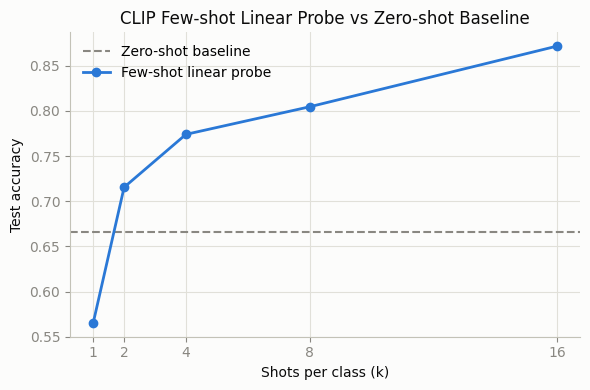

In [8]:
import matplotlib.pyplot as plt

ks_sorted = sorted(k_values)
accs = [few_shot_results[k] for k in ks_sorted]

fig, ax = plt.subplots(figsize=(6, 4), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

ax.axhline(zero_shot_accuracy, color="#898781", linestyle="--", linewidth=1.5, label="Zero-shot baseline")
ax.plot(ks_sorted, accs, color="#2a78d6", linewidth=2, marker="o", markersize=6, label="Few-shot linear probe")

ax.set_xlabel("Shots per class (k)", color="#0b0b0b")
ax.set_ylabel("Test accuracy", color="#0b0b0b")
ax.set_title("CLIP Few-shot Linear Probe vs Zero-shot Baseline", color="#0b0b0b")
ax.set_xticks(ks_sorted)
ax.grid(True, color="#e1e0d9", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("results/few_shot_accuracy.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

with open("results/clip_few_shot_results.json", "w") as f:
    json.dump({str(k): round(v, 4) for k, v in few_shot_results.items()}, f, indent=2)